# Main Notebook for whole diabetes risk prediction 


In [2]:
# %pip install -q pandas numpy matplotlib seaborn scikit-learn joblib streamlit

In [7]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from preprocessing import (
    load_data,
    clean_data,
    split_data,
    fit_preprocessors,
    transform,
    save_split,
)          # our preprocessing pre-defined functions

sns.set_theme(style="whitegrid") 

In [8]:
# loading the Dataset via predefined methods
df_raw = load_data()
df_raw.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [9]:
df_raw.shape

(100000, 9)

#### 100k Rows with 9 Columns/Features. 
##### We would need different numbers of features for different models but the meaning and features would be same

In [10]:
dfRaw = df_raw

In [11]:
dfRaw.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 8.0 MB


In [12]:
dfRaw.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [13]:
dfRaw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,100000,3,Female,58552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,100000.0,NaN,NaN,NaN,41.885856,22.51684,0.08,24.0,43.0,60.0,80.0
hypertension,100000.0,NaN,NaN,NaN,0.07485,0.26315,0.0,0.0,0.0,0.0,1.0
heart_disease,100000.0,NaN,NaN,NaN,0.03942,0.194593,0.0,0.0,0.0,0.0,1.0
smoking_history,100000,6,No Info,35816,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,100000.0,NaN,NaN,NaN,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,NaN,NaN,NaN,5.527507,1.070672,3.5,4.8,5.8,6.2,9.0
blood_glucose_level,100000.0,NaN,NaN,NaN,138.05806,40.708136,80.0,100.0,140.0,159.0,300.0
diabetes,100000.0,NaN,NaN,NaN,0.085,0.278883,0.0,0.0,0.0,0.0,1.0


with this single eda describe we know a lot about the dataset's features themselve.
1. there are two string data so we have to normalize and encode them.
2. there is lot of garbage in `smoking_history` feature.
3. Much more.

~ funny shi there is `0.08` year as datapoint in age like wha-


Now, standarization, normalization, duplicate removing, and null removing

In [14]:
dfRaw.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [15]:
# no null : D still we will see to frame
dfRaw.isnull().sum().to_frame("missing_values")

,missing_values
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


In [16]:
targetCounts = dfRaw["diabetes"].value_counts()
display(" so 8.5 % have diabetes " ) 
targetCounts

' so 8.5 % have diabetes '

diabetes
0    91500
1     8500
Name: count, dtype: int64

,counts,percentage
diabetes,,
0,91500,91.5
1,8500,8.5


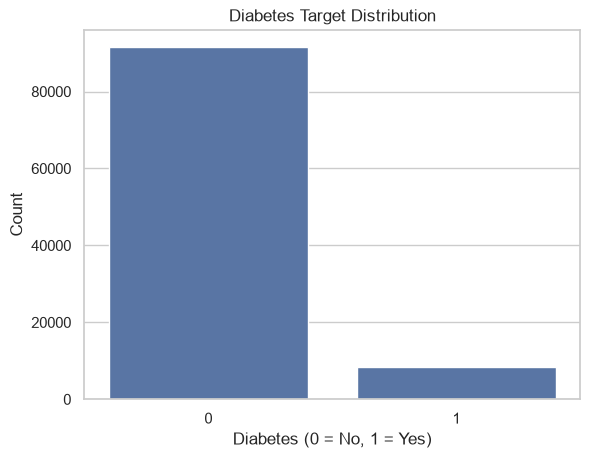

In [17]:
targetPercentage = (
    df_raw["diabetes"].value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

display(pd.DataFrame({
    "counts" : targetCounts,
    "percentage" : targetPercentage
}))

sns.countplot(data = dfRaw, x = "diabetes")
plt.title("Diabetes Target Distribution")
plt.xlabel("Diabetes (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()
    

 as earlier explained by me that there are two features in string.
which are known as categorial values or features. those are
`smoking_history` and `gender`

In [18]:
categorical_cols = ["gender", "smoking_history"]

for col in categorical_cols:
    print(f"\n{col.upper()} distribution:")
    display(df_raw[col].value_counts().to_frame("count"))

    print(f"{col.upper()} diabetes rate:")
    display(
        df_raw.groupby(col)["diabetes"]
        .agg(["count", "mean"])
        .rename(columns={"mean": "diabetes_rate"})
        .sort_values("diabetes_rate", ascending=False)
        .round(3)
    )


GENDER distribution:


,count
gender,
Female,58552
Male,41430
Other,18


GENDER diabetes rate:


,count,diabetes_rate
gender,,
Male,41430,0.097
Female,58552,0.076
Other,18,0.000



SMOKING_HISTORY distribution:


,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


SMOKING_HISTORY diabetes rate:


,count,diabetes_rate
smoking_history,,
former,9352,0.170
ever,4004,0.118
not current,6447,0.107
current,9286,0.102
never,35095,0.095
No Info,35816,0.041


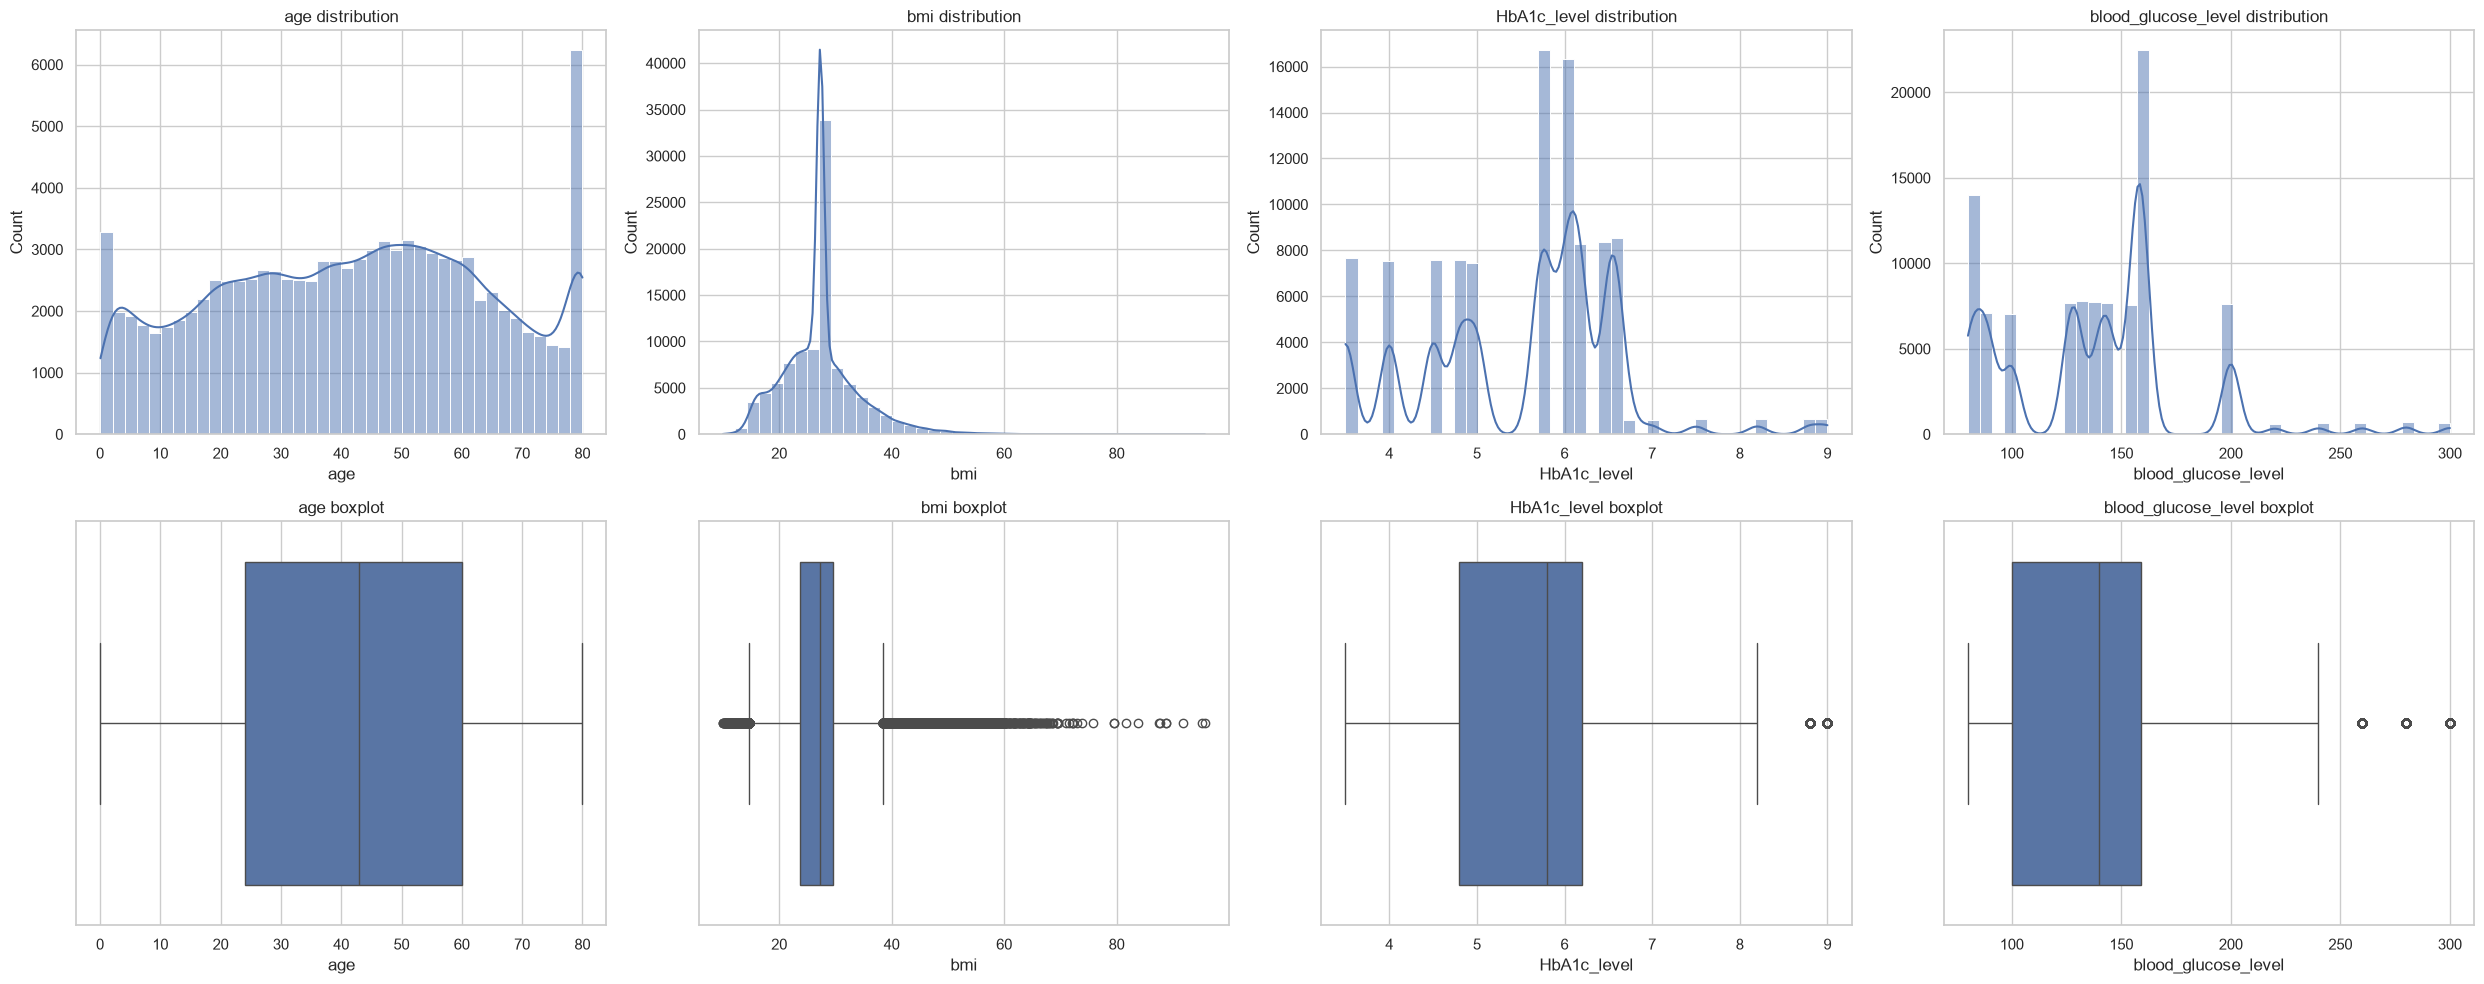

In [19]:
# now let's see the numerical distribution using subplots with box ( for outliers ) 
# and hist for various-ness

numeric_cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]

fig, axes = plt.subplots(2,4, figsize=(25,10))

for i, col in enumerate(numeric_cols):
    sns.histplot(data=df_raw, x=col, bins=40, kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"{col} distribution")

    sns.boxplot(data=df_raw, x=col, ax=axes[1, i])
    axes[1, i].set_title(f"{col} boxplot")

plt.tight_layout()
plt.show()

In [20]:
print("Age <= 0:", (df_raw["age"] <= 0).sum())
print("BMI < 10:", (df_raw["bmi"] < 10).sum())
print("BMI > 80:", (df_raw["bmi"] > 80).sum())
print("Gender = Other:", (df_raw["gender"] == "Other").sum())

# the data rules for age and bmi we check it and then clean it

display(df_raw[numeric_cols].quantile([0.01, 0.05, 0.50, 0.95, 0.99]).T)

Age <= 0: 0
BMI < 10: 0
BMI > 80: 9
Gender = Other: 18


,0.01,0.05,0.50,0.95,0.99
age,1.08,4.00,43.00,80.00,80.0000
bmi,14.60,16.82,27.32,39.49,48.7901
HbA1c_level,3.50,3.50,5.80,6.60,8.8000
blood_glucose_level,80.00,80.00,140.00,200.00,280.0000


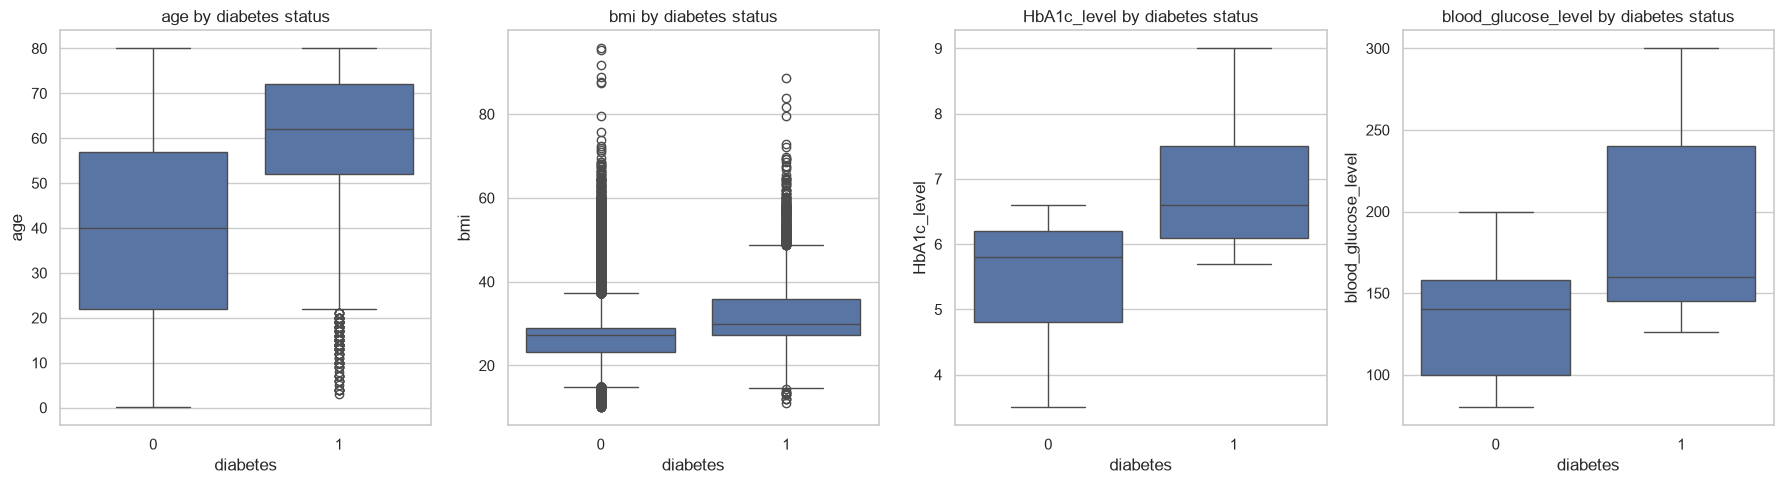

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for i, col in enumerate(numeric_cols):
    sns.boxplot(data=df_raw, x="diabetes", y=col, ax=axes[i])
    axes[i].set_title(f"{col} by diabetes status")

plt.tight_layout()
plt.show()

Checking the target with numeric values

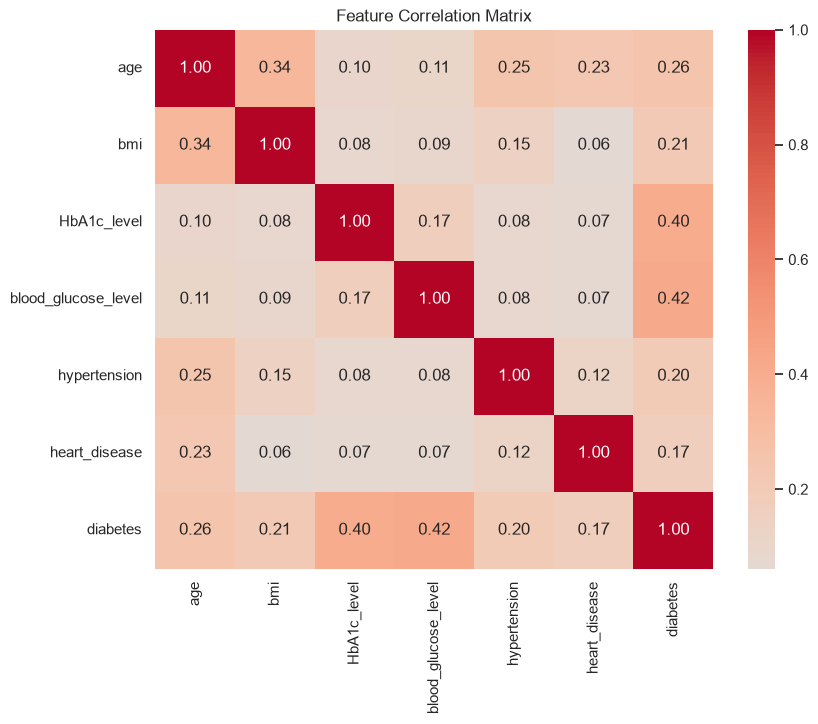

In [22]:
# ofcc we have to check correlation : D

correlation_cols = numeric_cols + ["hypertension", "heart_disease", "diabetes"]

plt.figure(figsize=(9, 7))
sns.heatmap(
    df_raw[correlation_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
)
plt.title("Feature Correlation Matrix")
plt.show()

as exploration and looking at distribution values is done we have to now Clean and Split. 

we already have functions in our preprocessing as `clean_data()` and `split_data()`

In [23]:
df_clean = clean_data(df_raw)     # by preprocessing function

print(f"Rows before cleaning: {len(df_raw):,}")
print(f"Rows after cleaning:  {len(df_clean):,}")
print(f"Rows removed:         {len(df_raw) - len(df_clean):,}")

display(df_clean.head())

Rows before cleaning: 100,000
Rows after cleaning:  96,119
Rows removed:         3,881


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


`100,000` -> `96,119` Rows 

In [24]:
clean_target_summary = (
    df_clean["diabetes"]
    .value_counts()
    .sort_index()
    .to_frame("count")
)

clean_target_summary["percentage"] = (
    df_clean["diabetes"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

display(clean_target_summary)

,count,percentage
diabetes,,
0,87640,91.18
1,8479,8.82


the percentage changes a lot after spliting

In [25]:
X_train, X_test, y_train, y_test = split_data(df_clean)    # by preprocessing function

print("Training features:", X_train.shape)
print("Testing features: ", X_test.shape)
print(f"Training positive rate: {y_train.mean():.4f}")
print(f"Testing positive rate:  {y_test.mean():.4f}")

Training features: (76895, 8)
Testing features:  (19224, 8)
Training positive rate: 0.0882
Testing positive rate:  0.0882


In [26]:
encoder, scaler = fit_preprocessors(X_train, save=True)   # by preprocessing function fitting

X_train_processed = transform(X_train, encoder, scaler)
X_test_processed = transform(X_test, encoder, scaler)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape: ", X_test_processed.shape)

display(X_train_processed.head())

Processed training shape: (76895, 11)
Processed testing shape:  (19224, 11)


,age,bmi,HbA1c_level,blood_glucose_level,gender_Male,smoking_history_current,smoking_history_former,smoking_history_never,smoking_history_not current,hypertension,heart_disease
28331,0.722552,-0.842213,0.899281,0.044642,0.0,1.0,0.0,0.0,0.0,0,0
68751,-1.780520,-1.182612,0.527143,0.533211,0.0,0.0,0.0,0.0,0.0,0,0
46518,-0.435453,0.661461,0.248039,-1.298920,0.0,1.0,0.0,0.0,0.0,0,0
23765,-0.747223,0.429102,-0.496236,1.510347,0.0,0.0,1.0,0.0,0.0,0,0
62969,0.678013,-0.000097,0.620177,0.411069,1.0,0.0,1.0,0.0,0.0,0,0


A Observation the data is way nicely normalize ( standard scaler ) because of this we have healthy data

In [27]:
# final step save the Splitted Data into .csv files
save_split(X_train, X_test, y_train, y_test)

print("Preprocessing complete.")

Preprocessing complete.


#### _Now, as EDA and Preprocessing is done. We can now train the models compare them and Save the Model Picle files. as Comparative Analysis is gonna be in backend-frontend onDemand by user. backend will handle rest._

In [28]:
import os
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

In [29]:
# We recall the Saved .csv train and test datasets

from preprocessing import load_split

X_train, X_test, y_train, y_test = load_split()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (76895, 11)
Testing data: (19224, 11)


In [30]:


"""
Let's create a Evaluation function that will be used as a layer of abstraction
between model's ( LR , KNN etc ) and Their trained scores

returns Score Map
with
: Model Name
: Accuracy
: Precision
: Recall
: F1 Score
: ROC-AUC
"""

def evaluate_model(name, model, X_test, y_test):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    scores = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
    }

    print(f"\n{name}")
    print("-" * len(name))
    print(classification_report(y_test, predictions))

    ConfusionMatrixDisplay.from_predictions(y_test, predictions)
    plt.title(f"{name} Confusion Matrix")
    plt.show()

    print("Accuracy:", scores["Accuracy"]) # gotta add this s

    return scores

### Logistic Regression 
This is the first model with Class Weight Balanced and Max Iteration set to 1000


Logistic Regression
-------------------
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17528
           1       0.43      0.88      0.57      1696

    accuracy                           0.89     19224
   macro avg       0.71      0.88      0.75     19224
weighted avg       0.94      0.89      0.90     19224



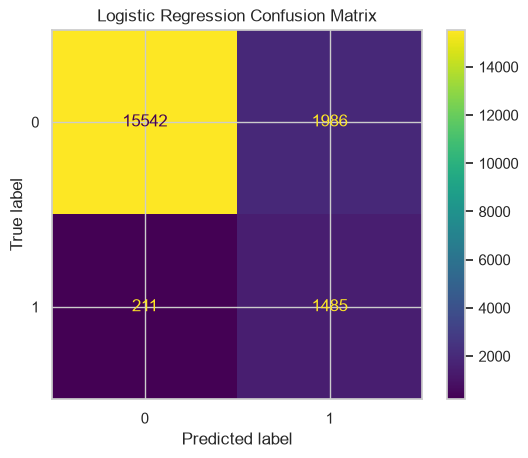

Accuracy: 0.885715771951727


In [31]:
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42,
)

lr_model.fit(X_train, y_train)
lr_results = evaluate_model("Logistic Regression", lr_model, X_test, y_test)

#### K-Nearest Neighbours
: D


KNN
---
              precision    recall  f1-score   support

           0       0.96      0.99      0.98     17528
           1       0.85      0.62      0.72      1696

    accuracy                           0.96     19224
   macro avg       0.91      0.80      0.85     19224
weighted avg       0.95      0.96      0.95     19224



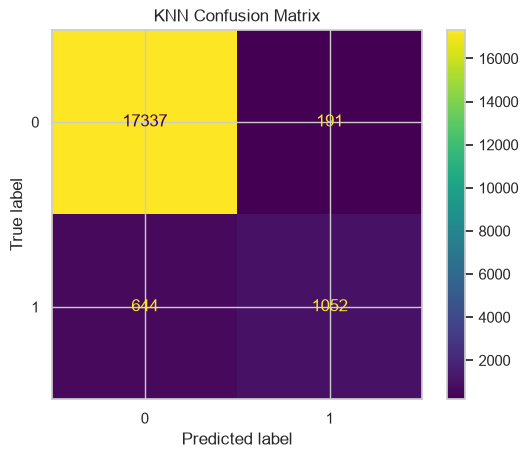

Accuracy: 0.9565647107781939


In [32]:
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    n_jobs=-1,
)

knn_model.fit(X_train, y_train)
knn_results = evaluate_model("KNN", knn_model, X_test, y_test)

#### Decision Trees
( cool stuff ) maybe


Decision Tree
-------------
              precision    recall  f1-score   support

           0       0.99      0.90      0.94     17528
           1       0.45      0.89      0.60      1696

    accuracy                           0.90     19224
   macro avg       0.72      0.89      0.77     19224
weighted avg       0.94      0.90      0.91     19224



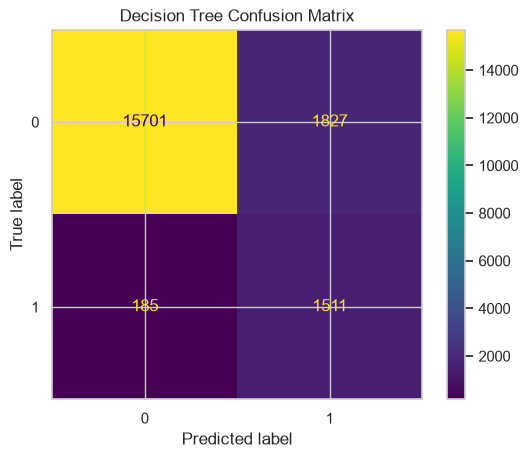

Accuracy: 0.8953391593841032


In [33]:
dt_model = DecisionTreeClassifier(
    max_depth=12,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
)

dt_model.fit(X_train, y_train)
dt_results = evaluate_model("Decision Tree", dt_model, X_test, y_test)

#### Random Forest 
lastly it's the best with balanced weight, 200 estimators, 16 would be max depth
along with all cores running


Random Forest
-------------
              precision    recall  f1-score   support

           0       0.99      0.91      0.95     17528
           1       0.50      0.90      0.64      1696

    accuracy                           0.91     19224
   macro avg       0.75      0.91      0.80     19224
weighted avg       0.95      0.91      0.92     19224



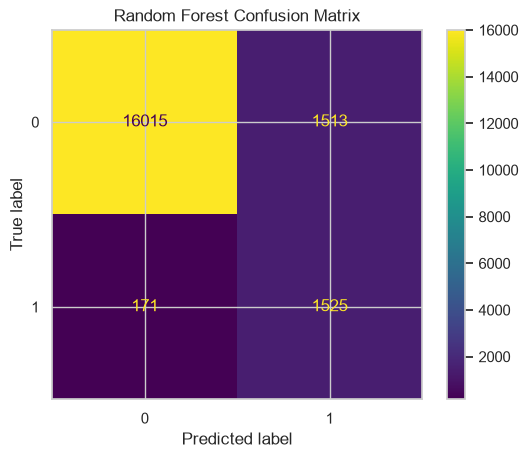

Accuracy: 0.912401165210154


In [34]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=16,
    min_samples_split=20,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

rf_model.fit(X_train, y_train)
rf_results = evaluate_model("Random Forest", rf_model, X_test, y_test)

In [35]:
"""
Comparing the Models Scores Now
"""

results_df = pd.DataFrame([
    lr_results,
    knn_results,
    dt_results,
    rf_results,
]).sort_values("F1 Score", ascending=False)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
1,KNN,0.9566,0.8463,0.6203,0.7159,0.9010
3,Random Forest,0.9124,0.5020,0.8992,0.6443,0.9760
2,Decision Tree,0.8953,0.4527,0.8909,0.6003,0.9641
0,Logistic Regression,0.8857,0.4278,0.8756,0.5748,0.9609


,Model,Specificity,False Negative Rate,Balanced Accuracy,PR-AUC (Average Precision),MCC,Brier Score,TP,TN,FP,FN
3,Random Forest,0.9137,0.1008,0.9064,0.8788,0.6320,0.0542,1525,16015,1513,171
2,Decision Tree,0.8958,0.1091,0.8933,0.8531,0.5890,0.0647,1511,15701,1827,185
0,Logistic Regression,0.8867,0.1244,0.8811,0.8108,0.5621,0.0794,1485,15542,1986,211
1,KNN,0.9891,0.3797,0.8047,0.7568,0.7028,0.0355,1052,17337,191,644


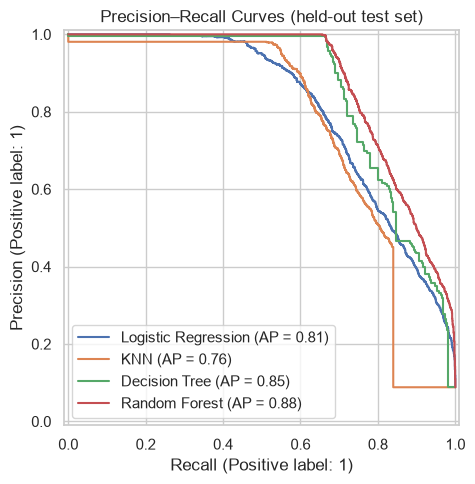

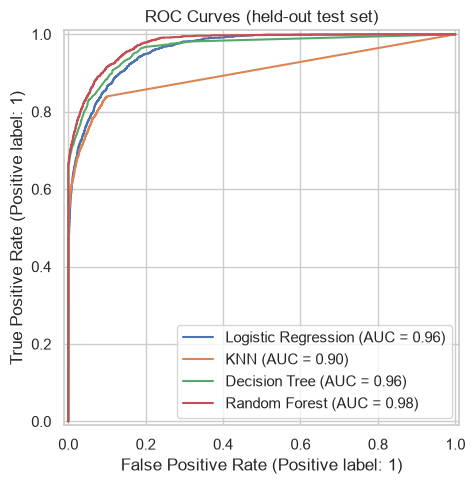

In [36]:
# brick by brick METRICS BEFORE HYPER TUNING and then Again Metrics 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, average_precision_score, balanced_accuracy_score,
    matthews_corrcoef, brier_score_loss, precision_recall_curve,
    PrecisionRecallDisplay, RocCurveDisplay
)

## we have 4 Models
candidate_models = {
    'Logistic Regression': lr_model,
    'KNN': knn_model,
    'Decision Tree': dt_model,
    'Random Forest': rf_model,
}

rows = []
fig_pr, ax_pr = plt.subplots(figsize=(7, 5))
fig_roc, ax_roc = plt.subplots(figsize=(7, 5))

for name, model in candidate_models.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    rows.append({
        'Model': name,
        'Specificity': tn / (tn + fp),
        'False Negative Rate': fn / (fn + tp),
        'Balanced Accuracy': balanced_accuracy_score(y_test, pred),
        'PR-AUC (Average Precision)': average_precision_score(y_test, prob),
        'MCC': matthews_corrcoef(y_test, pred),
        'Brier Score': brier_score_loss(y_test, prob),
        'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn,
    })
    PrecisionRecallDisplay.from_predictions(y_test, prob, name=name, ax=ax_pr)
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=ax_roc)

extra_results = pd.DataFrame(rows).sort_values('PR-AUC (Average Precision)', ascending=False)
display(extra_results.round(4))
ax_pr.set_title('Precision–Recall Curves (held-out test set)')
ax_roc.set_title('ROC Curves (held-out test set)')
fig_pr.tight_layout(); fig_roc.tight_layout()
fig_pr.savefig('precision_recall_curves.png', dpi=200, bbox_inches='tight')
fig_roc.savefig('roc_curves.png', dpi=200, bbox_inches='tight')
plt.show()


## TO help reading it afterworks 
# Interpretation:
# Specificity = TN/(TN+FP)   | False Negative Rate = FN/(FN+TP)
# Balanced accuracy = (recall + specificity)/2
# PR-AUC (average precision) is often informative for imbalanced classes.
# MCC ranges from -1 to 1, with 1 representing perfect classification.
# Lower Brier Score indicates better probability prediction, but compare calibration too.
# IMPORTANT: do NOT optimize your decision threshold on the final test set.
# Instead reserve a validation split or use cross-validation on the training partition.


## VISUALZIZEEESATIIONNN : DD

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import plot_tree
from sklearn.base import clone

In [38]:
def visualize_lr(model, X, title="Logistic Regression"):
    """
    Visualize trained Logistic Regression coefficients.
    Works with original and tuned LR models.
    """
    coefficients = pd.Series(
        model.coef_[0],
        index=X.columns
    ).sort_values()

    plt.figure(figsize=(11, 6))

    colors = [
        "tomato" if value < 0 else "seagreen"
        for value in coefficients
    ]

    coefficients.plot(
        kind="barh",
        color=colors
    )

    plt.axvline(0, color="black", linewidth=1)
    plt.title(f"{title} — Feature Coefficients")
    plt.xlabel("Coefficient (log-odds)")
    plt.ylabel("Feature")

    plt.tight_layout()
    plt.show()

In [39]:
def visualize_knn(
    model,
    X,
    y,
    title="KNN",
    sample_size=2000
):
    """
    Create a 2D PCA illustration of KNN.

    Fits a temporary KNN with the supplied model's
    hyperparameters on PCA-transformed data.

    Does not modify the original trained model.
    """
    X_sample = X.sample(
        n=min(sample_size, len(X)),
        random_state=42
    )

    y_sample = pd.Series(
        np.asarray(y),
        index=X.index
    ).loc[X_sample.index]

    # Reduce to 2D
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_sample)

    # Temporary visualization-only classifier
    knn_2d = KNeighborsClassifier(
        n_neighbors=model.n_neighbors,
        weights=model.weights,
        p=model.p,
        metric=model.metric
    )

    knn_2d.fit(X_pca, y_sample)

    # Mesh grid
    x_min, x_max = (
        X_pca[:, 0].min() - 1,
        X_pca[:, 0].max() + 1
    )

    y_min, y_max = (
        X_pca[:, 1].min() - 1,
        X_pca[:, 1].max() + 1
    )

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 180),
        np.linspace(y_min, y_max, 180)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    predictions = knn_2d.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(10, 7))

    plt.contourf(
        xx,
        yy,
        predictions,
        alpha=0.25,
        cmap="coolwarm"
    )

    plt.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=y_sample,
        cmap="coolwarm",
        s=12,
        alpha=0.65
    )

    explained = pca.explained_variance_ratio_.sum()

    plt.title(
        f"{title} — PCA Decision Regions\n"
        f"Explained Variance: {explained:.1%}"
    )

    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")

    plt.tight_layout()
    plt.show()

In [42]:
def visualize_dt(
    model,
    X,
    title="Decision Tree",
    depth=3
):
    """
    Visualize the first few levels of a trained
    Decision Tree classifier. 
    : D we have to CONSTAINT the Depth as it might blow up our memory 
    """
    plt.figure(figsize=(22, 11))

    plot_tree(
        model,
        feature_names=list(X.columns),
        class_names=["Non-diabetic", "Diabetic"],
        filled=True,
        rounded=True,
        max_depth=depth,
        fontsize=9,
        proportion=True
    )

    plt.title(
        f"{title} — First {depth} Levels",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

In [41]:
def visualize_rf(
    model,
    X,
    title="Random Forest",
    tree_index=0,
    depth=3
):
    """
    Visualize Random Forest feature importance
    and one tree from the ensemble.
    """

    # Feature importance
    importance = pd.Series(
        model.feature_importances_,
        index=X.columns
    ).sort_values()

    plt.figure(figsize=(11, 6))

    importance.plot(
        kind="barh",
        color="teal"
    )

    plt.title(f"{title} — Feature Importance")
    plt.xlabel("Mean Decrease in Impurity")
    plt.ylabel("Feature")

    plt.tight_layout()
    plt.show()

    # One tree from forest
    tree = model.estimators_[tree_index]

    plt.figure(figsize=(22, 11))

    plot_tree(
        tree,
        feature_names=list(X.columns),
        class_names=["Non-diabetic", "Diabetic"],
        filled=True,
        rounded=True,
        max_depth=depth,
        fontsize=9,
        proportion=True
    )

    plt.title(
        f"{title} — Tree #{tree_index + 1}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

## Trying to Hyper Tune all 4 Models 

we have lot of info to write here
all the hyperpara for our given 4 Models  :D

Initially, we trained four classification models using manually selected hyperparameters:

1. **Logistic Regression (LR)** — Linear probabilistic classifier.
2. **K-Nearest Neighbors (KNN)** — Distance-based classifier.
3. **Decision Tree (DT)** — Rule-based classifier.
4. **Random Forest (RF)** — Ensemble of multiple Decision Trees.

We then used **RandomizedSearchCV with 3-fold Stratified Cross-Validation** to explore alternative hyperparameter combinations.

**Why tune these models?**

- Improve generalization to unseen patient records.
- Reduce overfitting or underfitting.
- Find a better balance between precision and recall.
- Account for the dataset's class imbalance.
- Compare original and optimized model configurations.


In [43]:

import pandas as pd
import joblib
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

search_spaces = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, random_state=42),
        {
            "C": [0.01, 0.1, 1, 10, 100],
            "class_weight": [None, "balanced"],
        }
    ),
    "KNN": (
        KNeighborsClassifier(n_jobs=1),
        {
            "n_neighbors": [3, 5, 7, 11, 15, 21],
            "weights": ["uniform", "distance"],
            "p": [1, 2],
        }
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {
            "max_depth": [4, 6, 8, 12, 16, None],
            "min_samples_split": [2, 10, 20, 50],
            "min_samples_leaf": [1, 5, 10, 20],
            "criterion": ["gini", "entropy"],
            "class_weight": [None, "balanced"],
        }
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42, n_jobs=1),
        {
            "n_estimators": [100, 200, 300],
            "max_depth": [8, 12, 16, 20, None],
            "min_samples_split": [2, 10, 20],
            "min_samples_leaf": [1, 5, 10],
            "max_features": ["sqrt", 0.7],
            "class_weight": [None, "balanced", "balanced_subsample"],
        }
    ),
}


In [45]:

import time

tuned_models = {}
tuning_results = []

total_start = time.perf_counter()

for name, (model, params) in search_spaces.items():
    print(f"\nTuning {name}...")
    start = time.perf_counter()

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=params,
        n_iter=10,
        scoring="f1",
        cv=cv,
        n_jobs=2,
        random_state=42,
        refit=True,
        verbose=1
    )

    search.fit(X_train, y_train)

    elapsed = time.perf_counter() - start

    tuned_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV F1": search.best_score_,
        "Best Parameters": search.best_params_,
        "Time (seconds)": round(elapsed, 2),
        "Time (minutes)": round(elapsed / 60, 2)
    })

    print("Best parameters:", search.best_params_)
    print("Best CV F1:", round(search.best_score_, 4))
    print(f"Time taken: {elapsed:.2f}s ({elapsed / 60:.2f} min)")

total_elapsed = time.perf_counter() - total_start

tuning_df = pd.DataFrame(tuning_results)
display(tuning_df)

print(f"\nTOTAL TUNING TIME: {total_elapsed / 60:.2f} minutes")



Tuning Logistic Regression...
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters: {'class_weight': None, 'C': 0.1}
Best CV F1: 0.7322
Time taken: 17.89s (0.30 min)

Tuning KNN...
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters: {'weights': 'uniform', 'p': 1, 'n_neighbors': 7}
Best CV F1: 0.7285
Time taken: 209.92s (3.50 min)

Tuning Decision Tree...
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters: {'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 8, 'criterion': 'gini', 'class_weight': None}
Best CV F1: 0.8041
Time taken: 9.01s (0.15 min)

Tuning Random Forest...
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': None, 'class_weight': None}
Best CV F1: 0.8039
Time taken: 533.06s (8.88 min)


,Model,Best CV F1,Best Parameters,Time (seconds),Time (minutes)
0,Logistic Regression,0.732188,"{'class_weight': None, 'C': 0.1}",17.89,0.30
1,KNN,0.728469,"{'weights': 'uniform', 'p': 1, 'n_neighbors': 7}",209.92,3.50
2,Decision Tree,0.804064,"{'min_samples_split': 10, 'min_samples_leaf': ...",9.01,0.15
3,Random Forest,0.803909,"{'n_estimators': 300, 'min_samples_split': 2, ...",533.06,8.88



TOTAL TUNING TIME: 12.83 minutes



Evaluating Logistic Regression

Logistic Regression (Original)
------------------------------
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17528
           1       0.43      0.88      0.57      1696

    accuracy                           0.89     19224
   macro avg       0.71      0.88      0.75     19224
weighted avg       0.94      0.89      0.90     19224



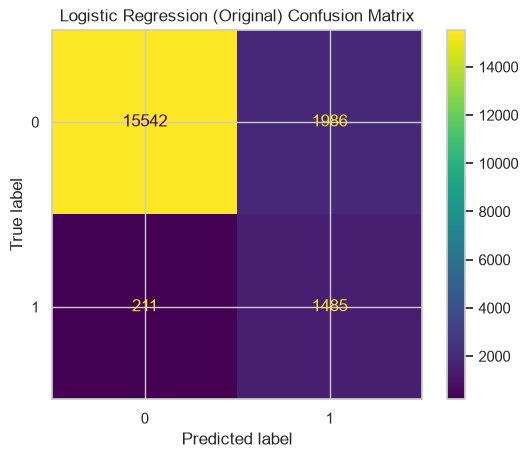

Accuracy: 0.885715771951727

Logistic Regression (Tuned)
---------------------------
              precision    recall  f1-score   support

           0       0.96      0.99      0.98     17528
           1       0.86      0.62      0.72      1696

    accuracy                           0.96     19224
   macro avg       0.91      0.81      0.85     19224
weighted avg       0.96      0.96      0.95     19224



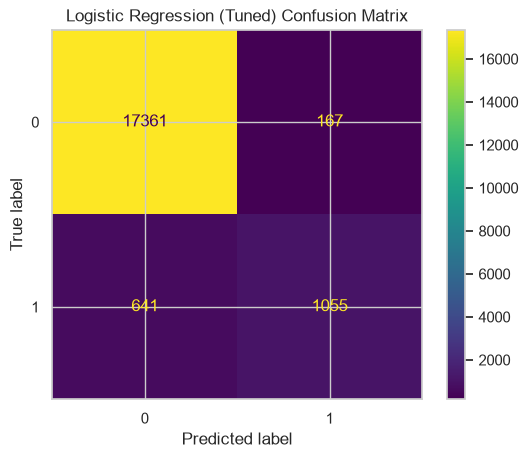

Accuracy: 0.9579692051602164

Evaluating KNN

KNN (Original)
--------------
              precision    recall  f1-score   support

           0       0.96      0.99      0.98     17528
           1       0.85      0.62      0.72      1696

    accuracy                           0.96     19224
   macro avg       0.91      0.80      0.85     19224
weighted avg       0.95      0.96      0.95     19224



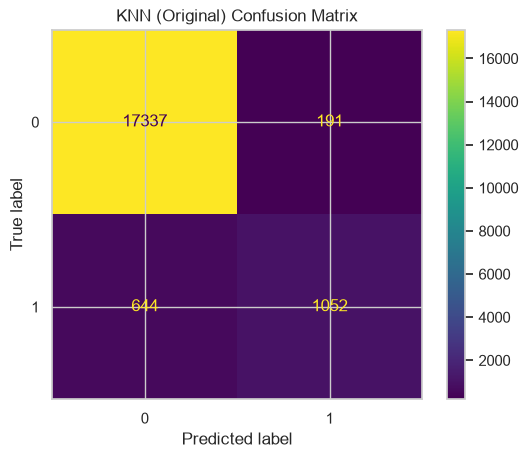

Accuracy: 0.9565647107781939

KNN (Tuned)
-----------
              precision    recall  f1-score   support

           0       0.96      0.99      0.98     17528
           1       0.92      0.60      0.72      1696

    accuracy                           0.96     19224
   macro avg       0.94      0.80      0.85     19224
weighted avg       0.96      0.96      0.96     19224



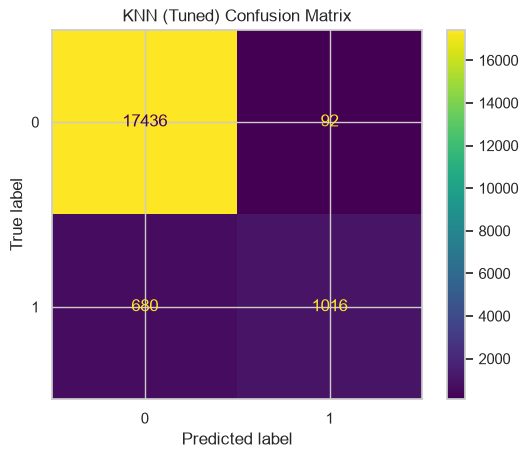

Accuracy: 0.9598418643362464

Evaluating Decision Tree

Decision Tree (Original)
------------------------
              precision    recall  f1-score   support

           0       0.99      0.90      0.94     17528
           1       0.45      0.89      0.60      1696

    accuracy                           0.90     19224
   macro avg       0.72      0.89      0.77     19224
weighted avg       0.94      0.90      0.91     19224



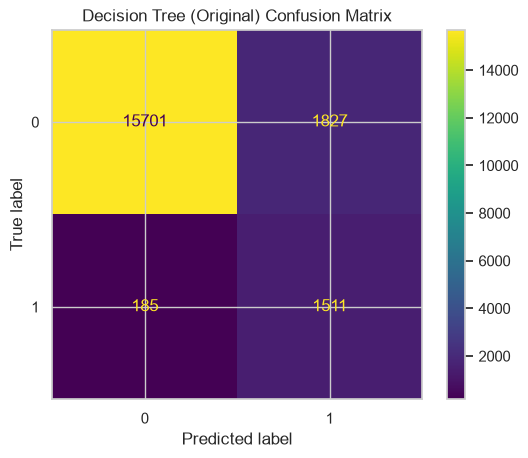

Accuracy: 0.8953391593841032

Decision Tree (Tuned)
---------------------
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17528
           1       0.98      0.67      0.79      1696

    accuracy                           0.97     19224
   macro avg       0.97      0.83      0.89     19224
weighted avg       0.97      0.97      0.97     19224



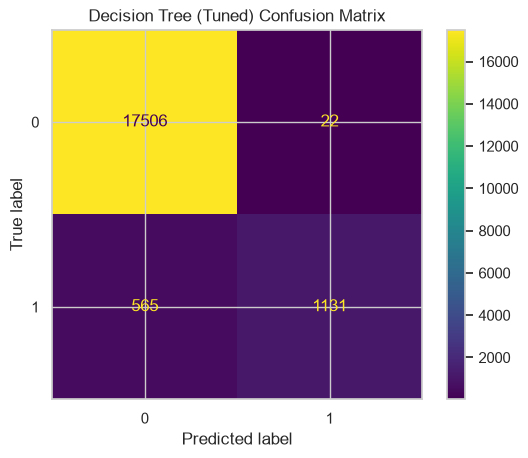

Accuracy: 0.9694652517686225

Evaluating Random Forest

Random Forest (Original)
------------------------
              precision    recall  f1-score   support

           0       0.99      0.91      0.95     17528
           1       0.50      0.90      0.64      1696

    accuracy                           0.91     19224
   macro avg       0.75      0.91      0.80     19224
weighted avg       0.95      0.91      0.92     19224



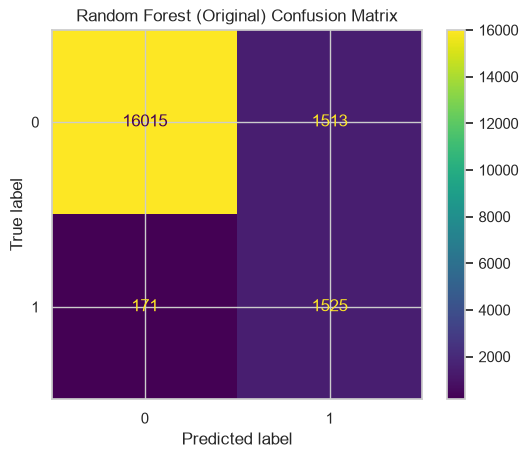

Accuracy: 0.912401165210154

Random Forest (Tuned)
---------------------
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17528
           1       0.99      0.67      0.80      1696

    accuracy                           0.97     19224
   macro avg       0.98      0.83      0.89     19224
weighted avg       0.97      0.97      0.97     19224



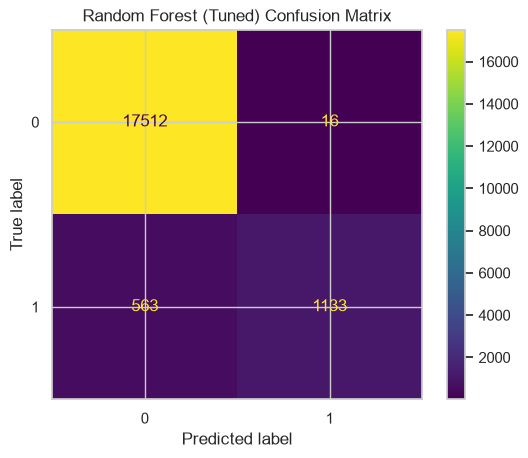

Accuracy: 0.9698813982521848


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression (Original),0.8857,0.4278,0.8756,0.5748,0.9609
1,Logistic Regression (Tuned),0.9580,0.8633,0.6221,0.7231,0.9607
2,KNN (Original),0.9566,0.8463,0.6203,0.7159,0.9010
3,KNN (Tuned),0.9598,0.9170,0.5991,0.7247,0.9147
4,Decision Tree (Original),0.8953,0.4527,0.8909,0.6003,0.9641
5,Decision Tree (Tuned),0.9695,0.9809,0.6669,0.7940,0.9725
6,Random Forest (Original),0.9124,0.5020,0.8992,0.6443,0.9760
7,Random Forest (Tuned),0.9699,0.9861,0.6680,0.7965,0.9728


In [46]:

original_models = {
    "Logistic Regression": lr_model,
    "KNN": knn_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

comparison = []

for name, original in original_models.items():
    print(f"\n{'=' * 50}")
    print(f"Evaluating {name}")
    print(f"{'=' * 50}")

    original_result = evaluate_model(
        name + " (Original)", original, X_test, y_test
    )

    tuned_result = evaluate_model(
        name + " (Tuned)", tuned_models[name], X_test, y_test
    )

    comparison.extend([original_result, tuned_result])

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(4))


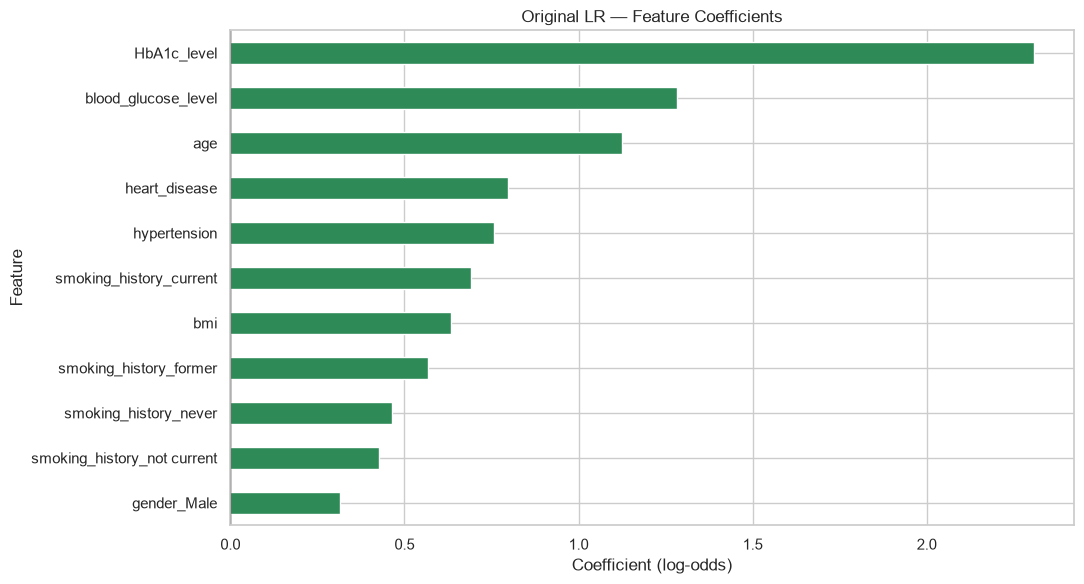

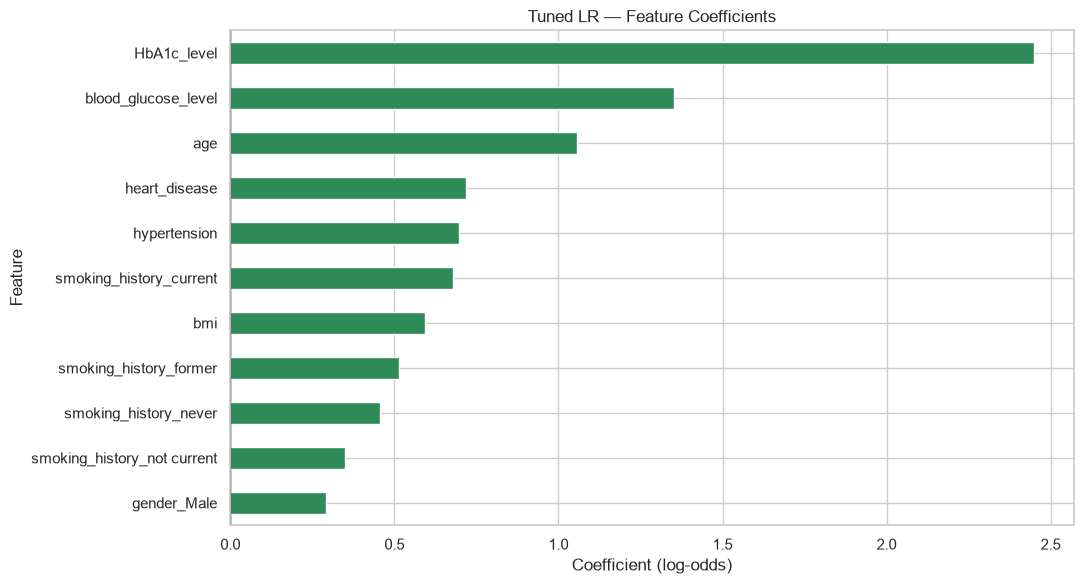

In [48]:
# Logistic Regression
visualize_lr(lr_model, X_train, "Original LR")
visualize_lr(tuned_models["Logistic Regression"], X_train, "Tuned LR")



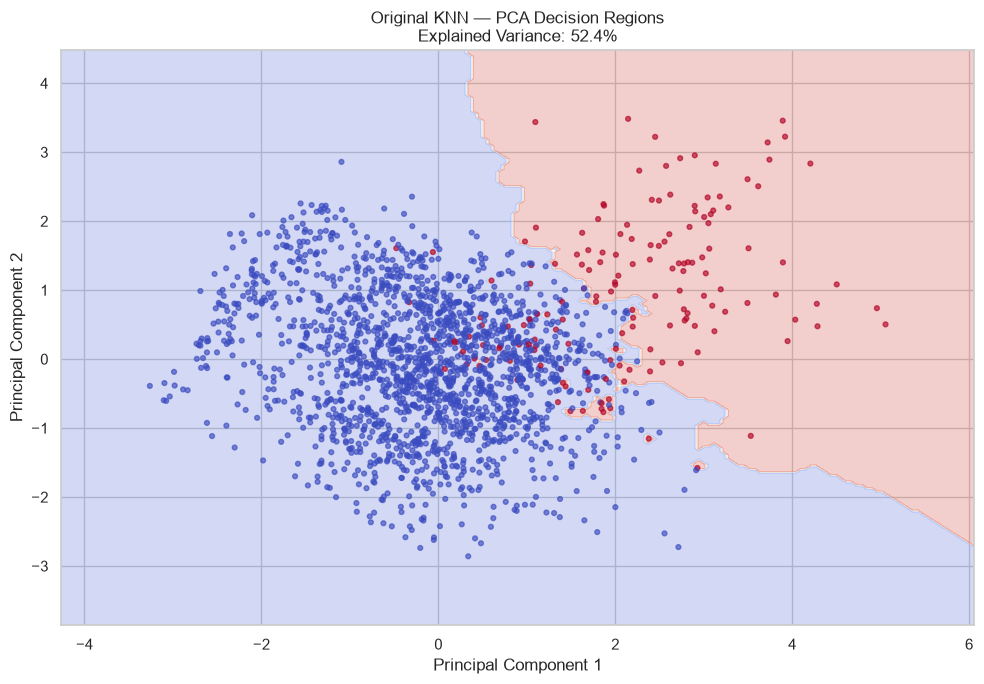

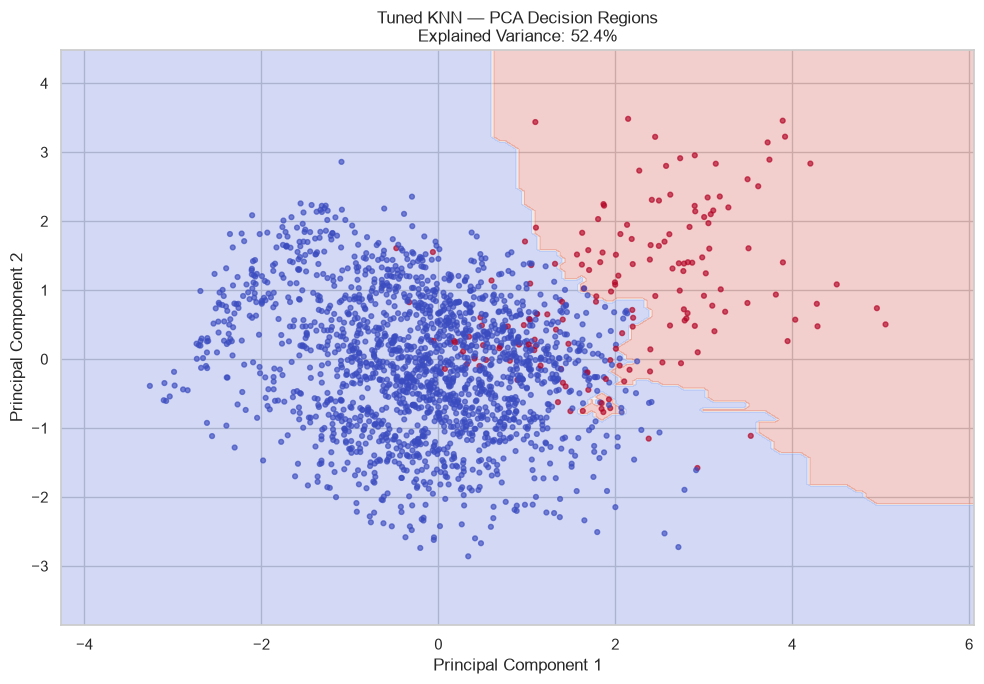

In [49]:

# KNN
visualize_knn(knn_model, X_train, y_train, "Original KNN")
visualize_knn(tuned_models["KNN"], X_train, y_train, "Tuned KNN")

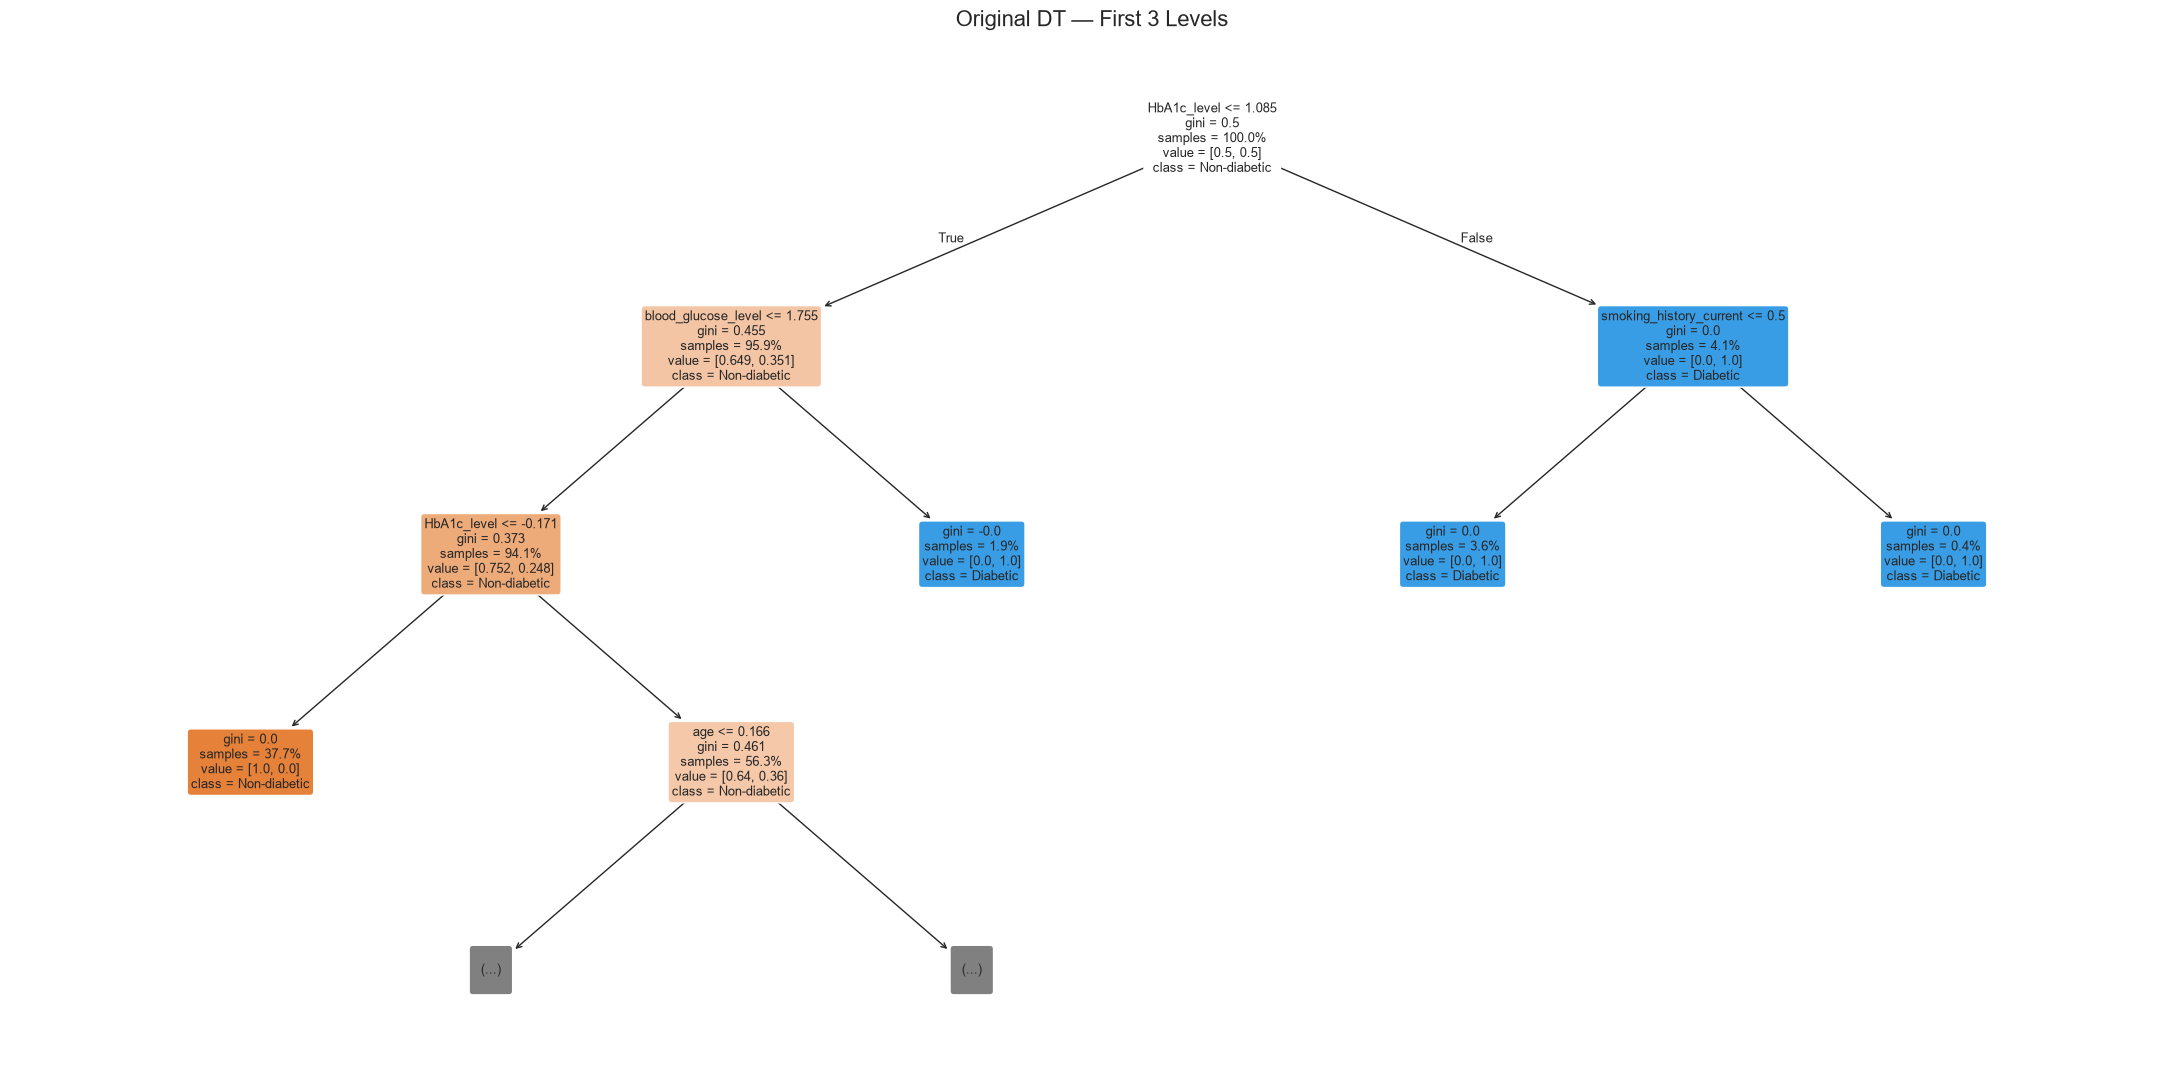

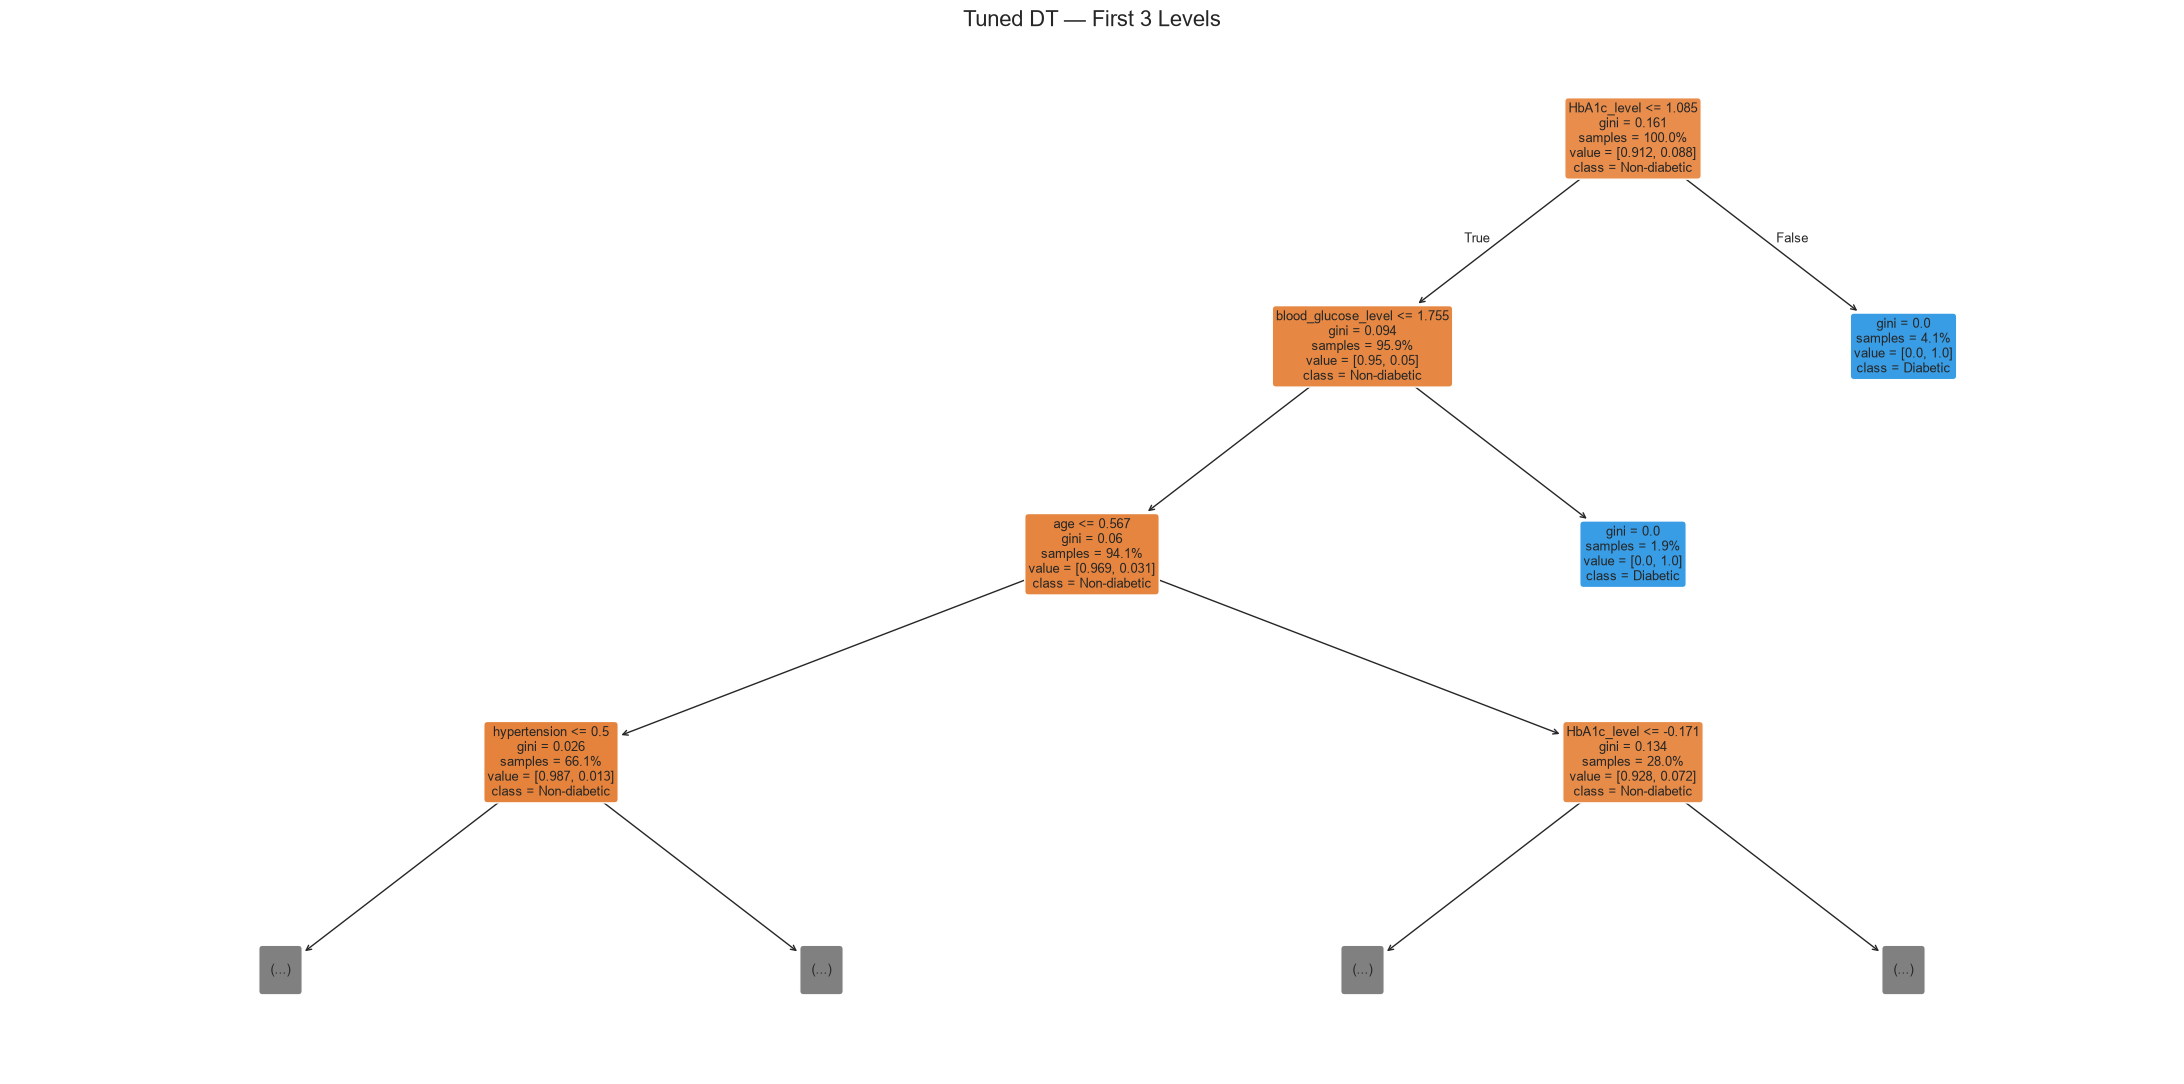

In [50]:

# Decision Tree
visualize_dt(dt_model, X_train, "Original DT")
visualize_dt(tuned_models["Decision Tree"], X_train, "Tuned DT")

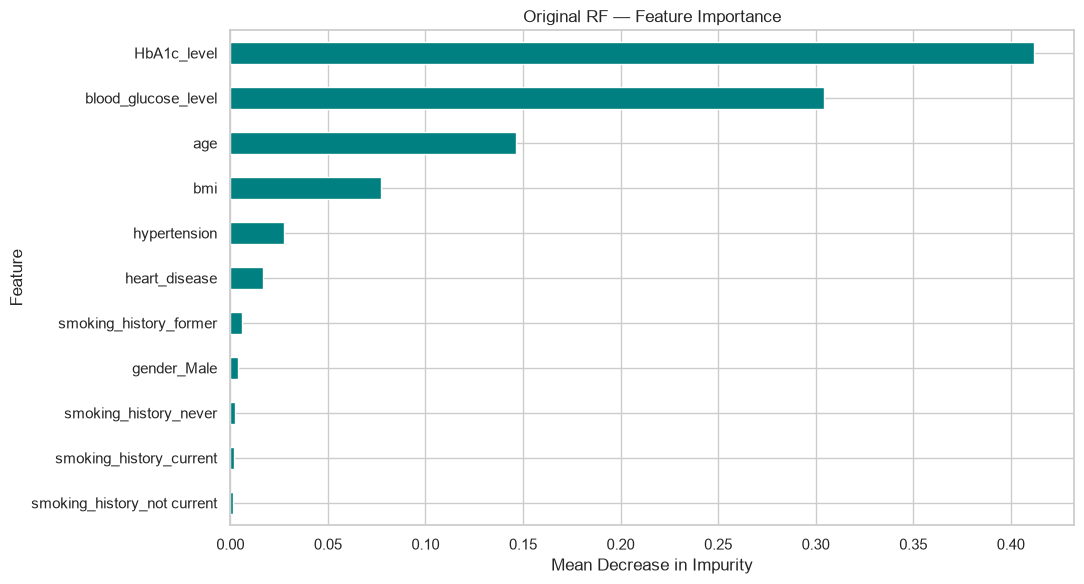

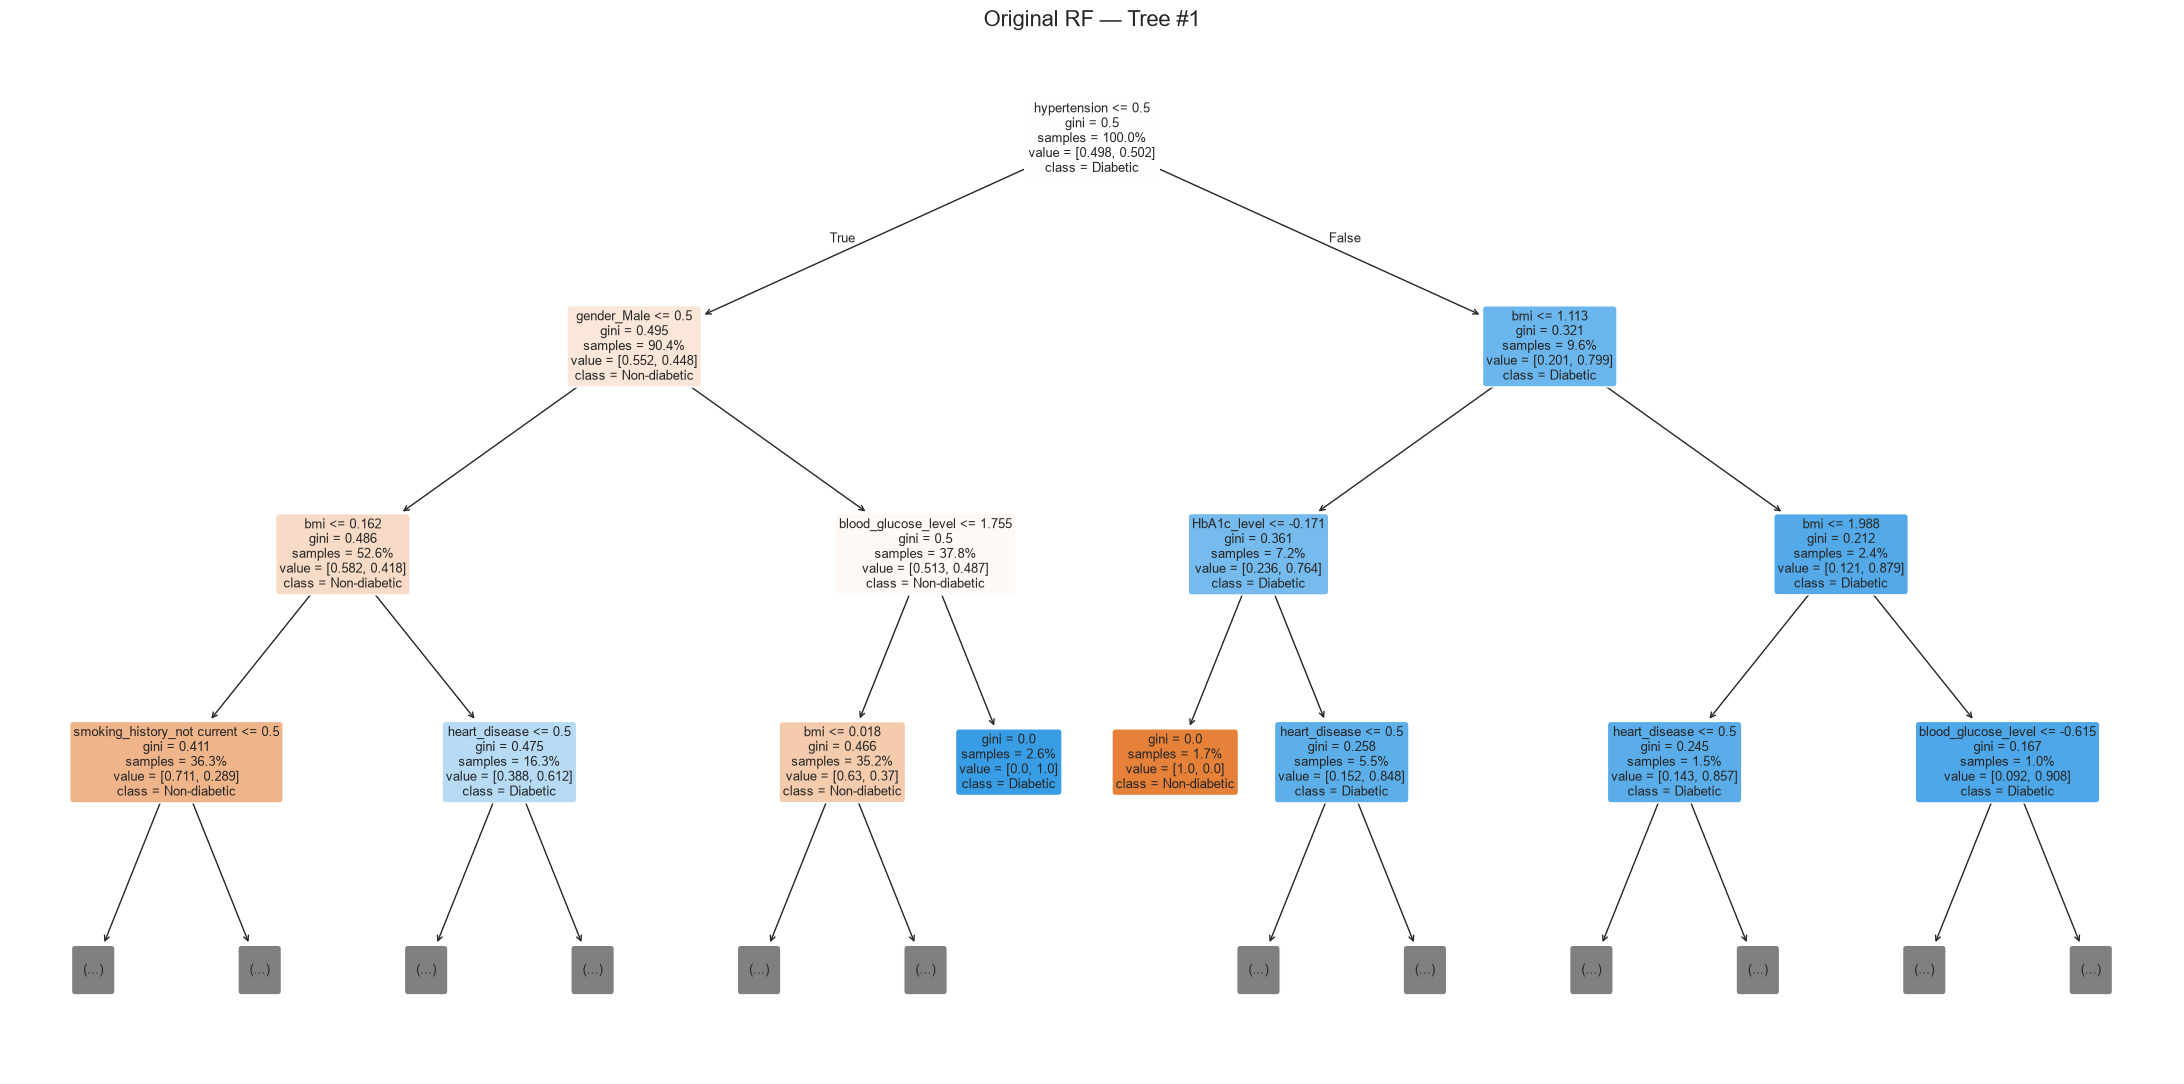

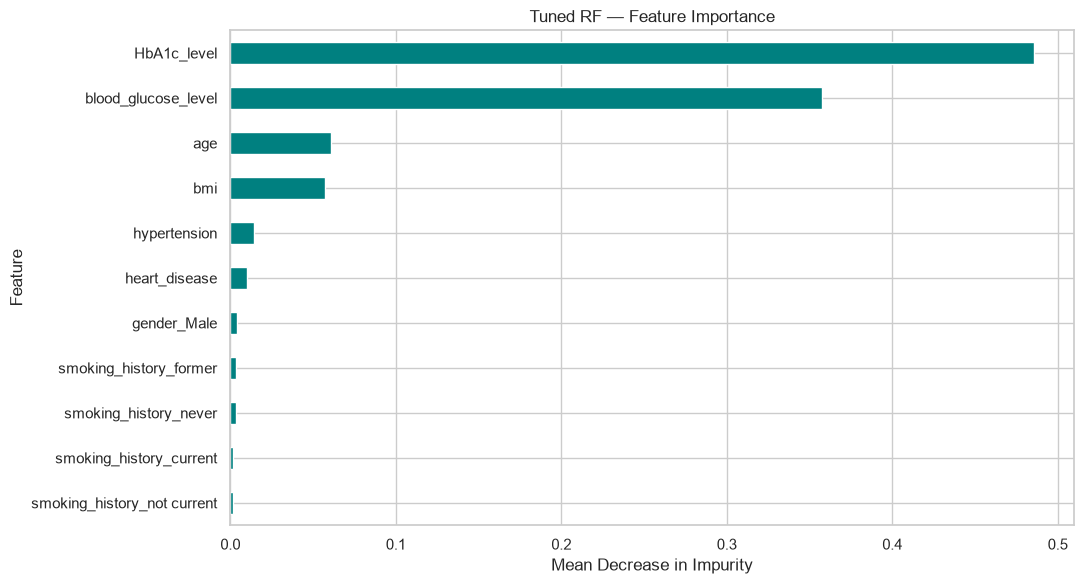

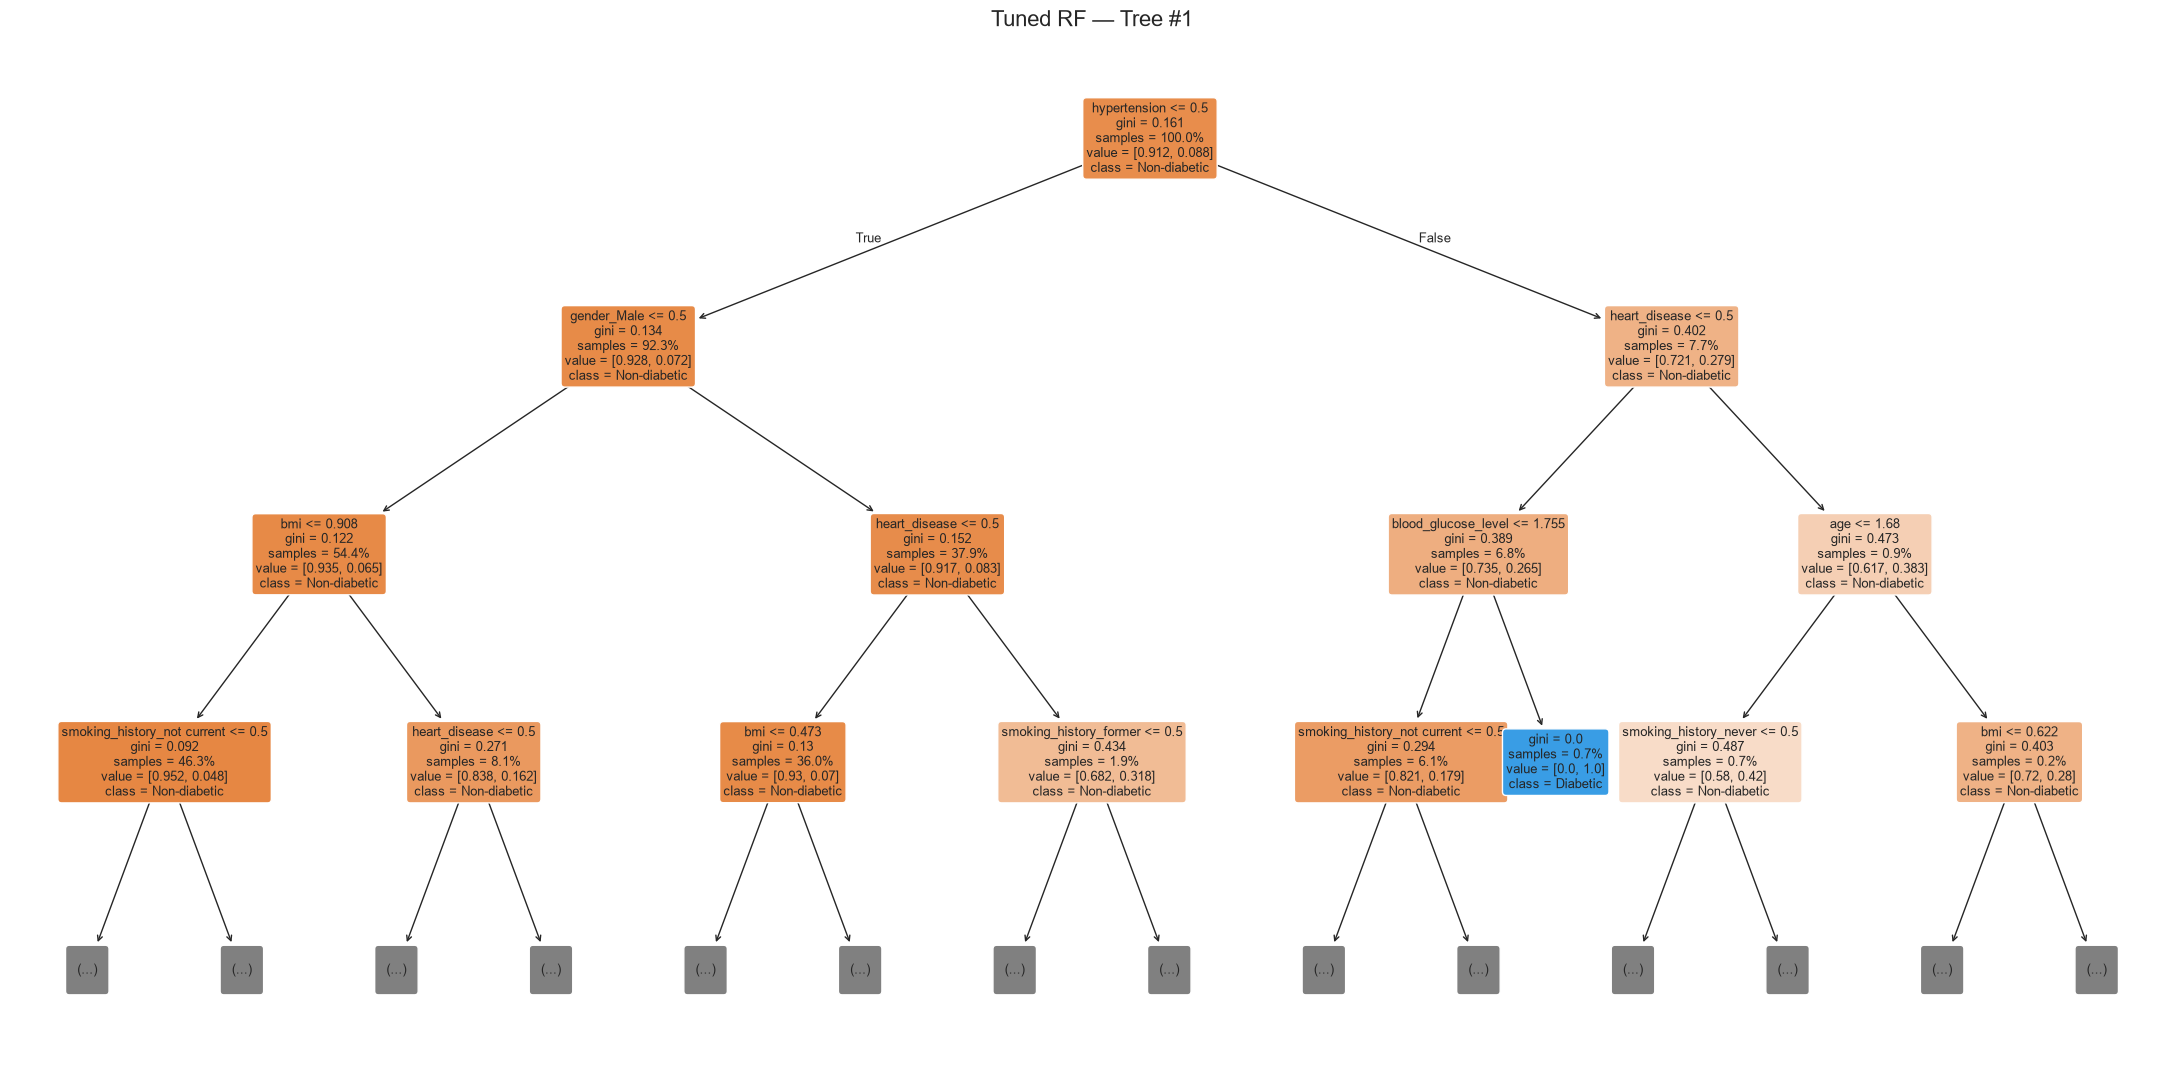

In [51]:


# Random Forest
visualize_rf(rf_model, X_train, "Original RF")
visualize_rf(tuned_models["Random Forest"], X_train, "Tuned RF")

In [53]:


## EXPORTING TUNED MODELS

from pathlib import Path
import joblib

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

filenames = {
    "Logistic Regression": "logistic_tuned.pkl",
    "KNN": "knn_tuned.pkl",
    "Decision Tree": "decision_tree_tuned.pkl",
    "Random Forest": "random_forest_tuned.pkl"
}

for name, filename in filenames.items():
    joblib.dump(tuned_models[name], model_dir / filename)
    print(f"Exported: {filename}")

Exported: logistic_tuned.pkl
Exported: knn_tuned.pkl
Exported: decision_tree_tuned.pkl
Exported: random_forest_tuned.pkl
